In [15]:
from __future__ import annotations

import sys
from pathlib import Path

import cv2
import numpy as np
import pdfplumber
import torch
from PIL import Image
from transformers import pipeline

ROOT = Path.cwd().resolve()
while not (ROOT / "norm-docs").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from normatives_pipeline.config import ocr_config, parser_config
from normatives_pipeline.parser.extractors import (
    extract_formulas,
    extract_unnumbered_formulas,
)
from normatives_pipeline.parser.models import Formula, ParsedDocument


In [16]:
pdf_path = ROOT / "norm-docs" / "СП 22.13330.2016.pdf"
pdf = pdfplumber.open(pdf_path)
pages = pdf.pages

print(f"страниц: {len(pages)}")


страниц: 222


In [17]:
DPI = 400
out_dir = ROOT / "normatives_pipeline" / "research" / "pages"
out_dir.mkdir(parents=True, exist_ok=True)

page_image_paths = []
for i, page in enumerate(pages, start=1):
    img = page.to_image(resolution=DPI).original
    path = out_dir / f"page_{i:03d}.png"
    img.save(path)
    page_image_paths.append(path)

print(f"изображений сохранено: {len(page_image_paths)}")


изображений сохранено: 222



0: 1024x736 1 title, 13 plain texts, 2 abandons, 1 isolate_formula, 1 formula_caption, 87.9ms
Speed: 8.5ms preprocess, 87.9ms inference, 1.7ms postprocess per image at shape (1, 3, 1024, 736)
найдено формул: 1
page_038_formula_0.png (1245, 1936, 1937, 2021) conf=0.91


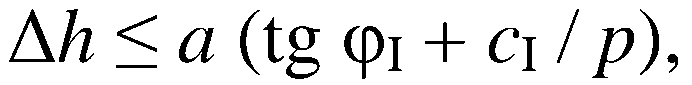

In [18]:
from doclayout_yolo import YOLOv10
from huggingface_hub import hf_hub_download
from IPython.display import Image, display

weights = hf_hub_download(
    "juliozhao/DocLayout-YOLO-DocStructBench",
    "doclayout_yolo_docstructbench_imgsz1024.pt",
)
model = YOLOv10(weights)

img = cv2.imread(str(ROOT / "normatives_pipeline" / "research" / "pages" / "page_038.png"))
res = model.predict(img, conf=0.25, imgsz=1024)

out_dir = ROOT / "normatives_pipeline" / "research" / "crops"
out_dir.mkdir(parents=True, exist_ok=True)

formula_crops = []
for r in res:
    for box, cls, conf in zip(r.boxes.xyxy, r.boxes.cls, r.boxes.conf):
        if r.names[int(cls)] == "isolate_formula":
            x1, y1, x2, y2 = [int(v) for v in box]
            crop = img[y1:y2, x1:x2]
            path = out_dir / f"page_038_formula_{len(formula_crops)}.png"
            cv2.imwrite(str(path), crop)
            formula_crops.append((path, (x1, y1, x2, y2), float(conf)))

print(f"найдено формул: {len(formula_crops)}")
for path, box, conf in formula_crops:
    print(path.name, box, f"conf={conf:.2f}")
    display(Image(filename=str(path)))


In [19]:
from pix2text import LatexOCR

recognizer = LatexOCR(device="cpu")

for path, box, conf in formula_crops:
    result = recognizer.recognize(str(path))
    print(f"{path.name}:  score={result['score']:.4f}")
    print(result["text"])
    print()


Could not find any ONNX files with standard file name decoder_model_merged.onnx, files found: [PosixPath('encoder_model.onnx'), PosixPath('decoder_model.onnx')]. Please make sure to pass a `file_name` and/or `subfolder` argument to `from_pretrained` when loading an ONNX file with non-standard file names.


100%|██████████| 1/1 [00:01<00:00,  1.06s/it]

page_038_formula_0.png:  score=0.9832
\Delta h \leq a \; ( \mathrm{t g} \; \varphi_{\mathrm{I}}+\, c_{\mathrm{I}} \, / \, p ) ,



$$\Delta h \leq a ~ ( \mathrm{t g} ~ \varphi_{\mathrm{I}}+\, c_{\mathrm{I}} \, / \, p ) ,$$

In [20]:
from normatives_pipeline.ocr.correct import correct_latex

for path, box, conf in formula_crops:
    raw = recognizer.recognize(str(path))["text"]
    corrected = correct_latex(raw)
    print(f"{path.name}:")
    print(f"  raw:       {raw}")
    print(f"  corrected: {corrected}")
    print()


100%|██████████| 1/1 [00:00<00:00,  1.11it/s]

page_038_formula_0.png:
  raw:       \Delta h \leq a \; ( \mathrm{t g} \; \varphi_{\mathrm{I}}+\, c_{\mathrm{I}} \, / \, p ) ,
  corrected: \Delta h \leq a ( \mathrm{tg} \varphi_{\mathrm{I}}+ c_{\mathrm{I}} / p )



$$\Delta h \leq a ( \mathrm{tg} \varphi_{\mathrm{I}}+ c_{\mathrm{I}} / p )$$

Could not find any ONNX files with standard file name decoder_model_merged.onnx, files found: [PosixPath('encoder_model.onnx'), PosixPath('decoder_model.onnx')]. Please make sure to pass a `file_name` and/or `subfolder` argument to `from_pretrained` when loading an ONNX file with non-standard file names.



0: 1024x736 15 plain texts, 2 abandons, 1 isolate_formula, 1 formula_caption, 87.3ms
Speed: 6.3ms preprocess, 87.3ms inference, 1.5ms postprocess per image at shape (1, 3, 1024, 736)


100%|██████████| 1/1 [00:00<00:00,  2.15it/s]


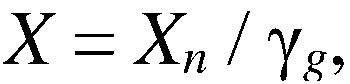

формула 5.1 (стр. 29): детекций 1, best_sim=0.682
  эталон:    X = \frac{X_n}{\gamma_g}
  результат: X=X_{n} \: / \: \gamma_{g}


0: 1024x736 1 title, 13 plain texts, 2 abandons, 1 isolate_formula, 1 formula_caption, 75.3ms
Speed: 10.5ms preprocess, 75.3ms inference, 1.9ms postprocess per image at shape (1, 3, 1024, 736)


100%|██████████| 1/1 [00:00<00:00,  1.01it/s]


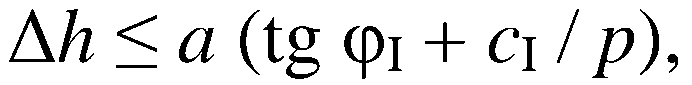

формула 5.5 (стр. 38): детекций 1, best_sim=0.939
  эталон:    \Delta h \leq a (\mathrm{tg}\,\varphi_I + c_I / p)
  результат: \Delta h \leq a ( \mathrm{tg} \varphi_{\mathrm{I}}+ c_{\mathrm{I}} / p )


0: 1024x736 1 title, 17 plain texts, 2 abandons, 1 isolate_formula, 1 formula_caption, 139.5ms
Speed: 7.1ms preprocess, 139.5ms inference, 2.8ms postprocess per image at shape (1, 3, 1024, 736)


100%|██████████| 1/1 [00:04<00:00,  4.64s/it]


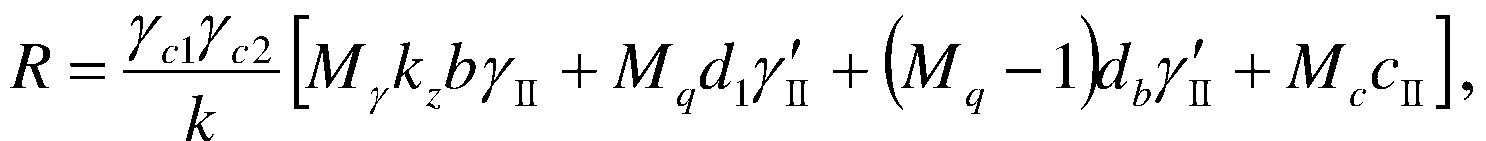

формула 5.7 (стр. 40): детекций 1, best_sim=0.728
  эталон:    R = \frac{\gamma_{c1}\gamma_{c2}}{k}\left[M_{\gamma} k_z b \gamma_{II} + M_q d_1 \gamma'_{II} + (M_q - 1) d_b \gamma'_{II} + M_c c_{II}\right]
  результат: R={\frac{\gamma_{c 1} \gamma_{c 2}} {k}} \big[ M_{_{\gamma}} k_{_{z}} b \gamma_{_{\mathrm{I I}}}+M_{_{q}} d_{_{1}} \gamma_{_{\mathrm{I I}}}^{\prime}+\big( M_{_{q}}-1 \big) d_{_{b}} \gamma_{_{\mathrm{I I}}}^{\prime}+M_{_{c}} c_{_{\mathrm{I I}}} \big]

mean similarity = 0.783


In [21]:
import importlib
import importlib.util
import re
import sys
import tomllib
import types

from IPython.display import display
from PIL import Image as PILImage
from doclayout_yolo import YOLOv10
from huggingface_hub import hf_hub_download
from latex2sympy2 import latex2sympy
from normatives_pipeline.ocr.correct import correct_latex


def _import_latex_ocr():
    spec = importlib.util.find_spec("pix2text")
    if spec is None or not spec.submodule_search_locations:
        raise ImportError("pix2text не найден")
    pkg = types.ModuleType("pix2text")
    pkg.__path__ = list(spec.submodule_search_locations)
    pkg.__package__ = "pix2text"
    sys.modules["pix2text"] = pkg
    importlib.import_module("pix2text.consts")
    importlib.import_module("pix2text.utils")
    importlib.import_module("pix2text.latex_ocr")
    return sys.modules["pix2text.latex_ocr"].LatexOCR


LatexOCR = _import_latex_ocr()

weights = hf_hub_download(
    "juliozhao/DocLayout-YOLO-DocStructBench",
    "doclayout_yolo_docstructbench_imgsz1024.pt",
)
detector = YOLOv10(weights)
recognizer = LatexOCR(device="cpu")


def detect_formulas(img):
    crops = []
    for r in detector.predict(img, conf=0.25, imgsz=1024):
        for box, cls in zip(r.boxes.xyxy, r.boxes.cls):
            if r.names[int(cls)] == "isolate_formula":
                x1, y1, x2, y2 = [int(v) for v in box]
                crops.append(img[y1:y2, x1:x2])
    return crops


def recognize_crop(crop):
    return correct_latex(recognizer.recognize(PILImage.fromarray(crop[..., ::-1]))["text"])


def normalize(latex: str) -> str:
    s = re.sub(r"\\mathrm\{([^}]*)\}", r"\1", latex)
    s = re.sub(r"\\operatorname\{([^}]*)\}", r"\1", s)
    s = re.sub(r"\\left|\\right|\\,|\\!|\\;|~", "", s)
    s = re.sub(r"\\[bB]igg?[lrm]?", "", s)
    for _ in range(3):
        s2 = re.sub(r"_\{\s*_\{([^{}]*)\}\s*\}", r"_{\1}", s)
        s2 = re.sub(r"\^\{\s*\^\{([^{}]*)\}\s*\}", r"^{\1}", s2)
        if s2 == s:
            break
        s = s2
    return re.sub(r"\s+", "", s)


def canonical(latex: str):
    s = normalize(latex)
    try:
        return latex2sympy(s)
    except Exception:
        return s


validation = tomllib.loads(
    (ROOT / "normatives_pipeline" / "research" / "validation.toml").read_text(encoding="utf-8")
)["formula"]

results = []
for entry in validation:
    page_path = ROOT / "normatives_pipeline" / "research" / "pages" / f"page_{entry['page']:03d}.png"
    img = cv2.imread(str(page_path))
    crops = detect_formulas(img)
    preds = [recognize_crop(c) for c in crops]
    et = canonical(entry["latex"])

    match_idx = next((i for i, p in enumerate(preds) if canonical(p) == et), None)
    ok = match_idx is not None

    for c in crops:
        display(PILImage.fromarray(c[..., ::-1]))

    print(f"формула {entry['number']} (стр. {entry['page']}): детекций {len(preds)}, match={ok}")
    print(f"  эталон:    {entry['latex']}")
    for p in preds:
        print(f"  результат: {p}")
    print()

    results.append((entry["number"], entry["page"], ok))

print(f"accuracy = {sum(1 for r in results if r[2])}/{len(results)}")


  эталон:    $$\Delta h \leq a (\mathrm{tg}\,\varphi_I + c_I / p)$$
  результат: $$\Delta h \leq a ( \mathrm{tg} \varphi_{\mathrm{I}}+ c_{\mathrm{I}} / p )$$

Эталон: $$R = \frac{\gamma_{c1}\gamma_{c2}}{k}\left[M_{\gamma} k_z b \gamma_{II} + M_q d_1 \gamma'_{II} + (M_q - 1) d_b \gamma'_{II} + M_c c_{II}\right]$$

Результат:
$$
R={\frac{\gamma_{c 1} \gamma_{c 2}} {k}} \big[ M_{_{\gamma}} k_{_{z}} b \gamma_{_{\mathrm{I I}}}+M_{_{q}} d_{_{1}} \gamma_{_{\mathrm{I I}}}^{\prime}+\big( M_{_{q}}-1 \big) d_{_{b}} \gamma_{_{\mathrm{I I}}}^{\prime}+M_{_{c}} c_{_{\mathrm{I I}}} \big]
$$

In [ ]:
import urllib.request
import zipfile

DATA_DIR = ROOT / "normatives_pipeline" / "research" / "data"
DATA_DIR.mkdir(parents=True, exist_ok=True)

BASE = "https://zenodo.org/api/records/7738969/files"

dataset_dir = DATA_DIR / "im2latex-230k"
images_dir = dataset_dir / "generated_png_images"
formulas_file = dataset_dir / "final_png_formulas.txt"

if not (images_dir.exists() and formulas_file.exists()):
    dataset_dir.mkdir(parents=True, exist_ok=True)

    zip_path = DATA_DIR / "PRINTED_TEX_230k.zip"
    if not zip_path.exists():
        print("скачиваем PRINTED_TEX_230k.zip (~1 ГБ)…")
        urllib.request.urlretrieve(f"{BASE}/PRINTED_TEX_230k.zip/content", zip_path)

    print("распаковываем…")
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(dataset_dir)
    zip_path.unlink()

    print("готово:", dataset_dir)
else:
    print("датасет уже есть:", dataset_dir)
